In [2]:
import pandas as pd
import numpy as np

# Load data
df = pd.read_csv('Dataset.csv')

# Look at the ratings
print("Rating Categories and Counts:")
print(df['rating'].value_counts())

Rating Categories and Counts:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [3]:
# 1. Define our top categories based on the data
top_categories = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG']

# 2. Group everything else into 'Other'
df['rating_clean'] = df['rating'].apply(lambda x: x if x in top_categories else 'Other')

# 3. Check the new distribution
print("Cleaned Rating Counts:")
print(df['rating_clean'].value_counts())

Cleaned Rating Counts:
rating_clean
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Other     352
TV-Y7     333
TV-Y      306
PG        287
Name: count, dtype: int64


In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# 1. Clean the genres (Remove TV/Movies and lowercase)
df['listed_in'] = df['listed_in'].fillna('')
df['clean_genres'] = df['listed_in'].str.replace(r'TV\s*|Movies?\s*', '', regex=True).str.lower()

# 2. Extract Duration (Convert "90 min" -> 90)
def extract_duration(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0
df['duration_num'] = df['duration'].apply(extract_duration)

# 3. Handle Release Year
df['release_year'] = df['release_year'].fillna(2010) 

# 4. Vectorize Genres
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
genres_matrix = tfidf.fit_transform(df['clean_genres'])

# 5. Combine Features (Genres + Duration + Year)
duration_array = df['duration_num'].values.reshape(-1, 1)
year_array = df['release_year'].values.reshape(-1, 1)

X = hstack((genres_matrix, duration_array, year_array))
y = df['rating_clean']

print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape: {y.shape}")

Feature Matrix Shape: (8790, 44)
Target Vector Shape: (8790,)


In [5]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# 1. Load Data
df = pd.read_csv('Dataset.csv')

# 2. Clean the Target (Grouping rare ratings)
top_categories = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG']
df['rating_clean'] = df['rating'].apply(lambda x: x if x in top_categories else 'Other')

# 3. Clean Genres
df['listed_in'] = df['listed_in'].fillna('')
df['clean_genres'] = df['listed_in'].str.replace(r'TV\s*|Movies?\s*', '', regex=True).str.lower()

# 4. Extract Duration
def extract_duration(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0
df['duration_num'] = df['duration'].apply(extract_duration)

# 5. Handle Release Year
df['release_year'] = df['release_year'].fillna(2010)

# 6. Vectorize Genres
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
genres_matrix = tfidf.fit_transform(df['clean_genres'])

# 7. Combine ALL Features (Genres + Duration + Year)
duration_array = df['duration_num'].values.reshape(-1, 1)
year_array = df['release_year'].values.reshape(-1, 1)

# THIS is the line you missed: hstack combines all three!
X = hstack((genres_matrix, duration_array, year_array))
y = df['rating_clean']

print(f"✅ Feature Matrix Shape: {X.shape}")
print(f"✅ Target Vector Shape: {y.shape}")

# Let's verify the target classes
print("\nTarget Classes:")
print(y.value_counts())

✅ Feature Matrix Shape: (8790, 44)
✅ Target Vector Shape: (8790,)

Target Classes:
rating_clean
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Other     352
TV-Y7     333
TV-Y      306
PG        287
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Initialize the Multi-Class Random Forest
# We use class_weight='balanced' again to handle the imbalanced ratings
rf_multi = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# 3. Train the model
print("Training Multi-Class Model... (This might take 10-15 seconds)")
rf_multi.fit(X_train, y_train)

# 4. Predict and Evaluate
y_pred_multi = rf_multi.predict(X_test)
print(f"\n🎯 Multi-Class Accuracy: {accuracy_score(y_test, y_pred_multi) * 100:.2f}%\n")
print("📊 Classification Report:")
print(classification_report(y_test, y_pred_multi))

Training Multi-Class Model... (This might take 10-15 seconds)

🎯 Multi-Class Accuracy: 48.01%

📊 Classification Report:
              precision    recall  f1-score   support

       Other       0.23      0.21      0.22        70
          PG       0.51      0.52      0.51        58
       PG-13       0.44      0.38      0.41        98
           R       0.45      0.44      0.44       160
       TV-14       0.45      0.46      0.45       431
       TV-MA       0.58      0.59      0.59       641
       TV-PG       0.26      0.26      0.26       172
        TV-Y       0.53      0.57      0.55        61
       TV-Y7       0.52      0.54      0.53        67

    accuracy                           0.48      1758
   macro avg       0.44      0.44      0.44      1758
weighted avg       0.48      0.48      0.48      1758



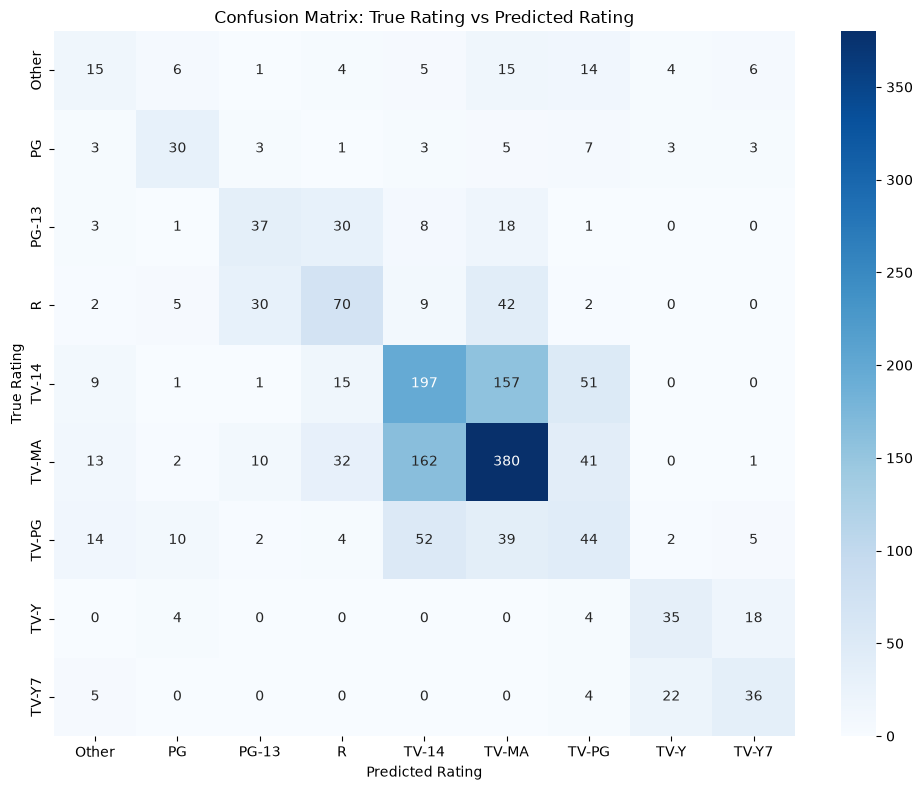

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create the confusion matrix
cm = confusion_matrix(y_test, y_pred_multi, labels=rf_multi.classes_)

# 2. Plot it
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=rf_multi.classes_, yticklabels=rf_multi.classes_)
plt.title('Confusion Matrix: True Rating vs Predicted Rating')
plt.xlabel('Predicted Rating')
plt.ylabel('True Rating')
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Define the "Grid" of options we want to test
param_grid = {
    'n_estimators': [50, 100],      # Try 50 trees and 100 trees
    'max_depth': [10, 20, None],    # Try shallow trees, medium trees, and unlimited depth
    'min_samples_split': [2, 5]     # How many samples needed to split a node?
}

# 2. Initialize the base model
rf_base = RandomForestClassifier(random_state=42, class_weight='balanced')

# 3. Set up GridSearchCV
# cv=3 means 3-fold Cross-Validation (it splits the training data into 3 parts to test the settings)
grid_search = GridSearchCV(
    estimator=rf_base, 
    param_grid=param_grid, 
    cv=3, 
    scoring='f1_macro', # We optimize for Macro F1, not just accuracy!
    n_jobs=-1,          # Use all CPU cores for speed
    verbose=1           # Print progress
)

print("Starting Hyperparameter Tuning... (This will take a minute or two)")
grid_search.fit(X_train, y_train)

# 4. See the best settings found
print(f"\n✅ Best Parameters Found: {grid_search.best_params_}")
print(f"✅ Best Cross-Validation Score: {grid_search.best_score_:.4f}")

Starting Hyperparameter Tuning... (This will take a minute or two)
Fitting 3 folds for each of 12 candidates, totalling 36 fits

✅ Best Parameters Found: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
✅ Best Cross-Validation Score: 0.4740


In [1]:
# 1. Train the final optimized model
rf_final = RandomForestClassifier(
    max_depth=10, 
    min_samples_split=5, 
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced'
)

rf_final.fit(X_train, y_train)

# 2. Predict on the test set
y_pred_final = rf_final.predict(X_test)

# 3. Evaluate
print(f"🎯 Final Optimized Accuracy: {accuracy_score(y_test, y_pred_final) * 100:.2f}%\n")
print("📊 Final Classification Report:")
print(classification_report(y_test, y_pred_final))

NameError: name 'RandomForestClassifier' is not defined

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load and clean target
df = pd.read_csv('Dataset.csv')
top_categories = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG']
df['rating_clean'] = df['rating'].apply(lambda x: x if x in top_categories else 'Other')

# 2. Clean genres
df['listed_in'] = df['listed_in'].fillna('')
df['clean_genres'] = df['listed_in'].str.replace(r'TV\s*|Movies?\s*', '', regex=True).str.lower()

# 3. Extract duration
def extract_duration(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0
df['duration_num'] = df['duration'].apply(extract_duration)

# 4. Release year
df['release_year'] = df['release_year'].fillna(2010)

# 5. Vectorize
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
genres_matrix = tfidf.fit_transform(df['clean_genres'])

# 6. Combine Features
duration_array = df['duration_num'].values.reshape(-1, 1)
year_array = df['release_year'].values.reshape(-1, 1)
X = hstack((genres_matrix, duration_array, year_array))
y = df['rating_clean']

# 7. Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 8. Train Final Optimized Model
rf_final = RandomForestClassifier(
    max_depth=10, 
    min_samples_split=5, 
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced'
)
rf_final.fit(X_train, y_train)

# 9. Evaluate
y_pred_final = rf_final.predict(X_test)
print(f"🎯 Final Optimized Accuracy: {accuracy_score(y_test, y_pred_final) * 100:.2f}%\n")
print("📊 Final Classification Report:")
print(classification_report(y_test, y_pred_final))

🎯 Final Optimized Accuracy: 46.25%

📊 Final Classification Report:
              precision    recall  f1-score   support

       Other       0.14      0.20      0.17        70
          PG       0.52      0.66      0.58        58
       PG-13       0.31      0.51      0.38        98
           R       0.41      0.53      0.46       160
       TV-14       0.45      0.52      0.48       431
       TV-MA       0.72      0.43      0.54       641
       TV-PG       0.24      0.26      0.25       172
        TV-Y       0.55      0.69      0.61        61
       TV-Y7       0.51      0.57      0.54        67

    accuracy                           0.46      1758
   macro avg       0.43      0.48      0.45      1758
weighted avg       0.51      0.46      0.47      1758



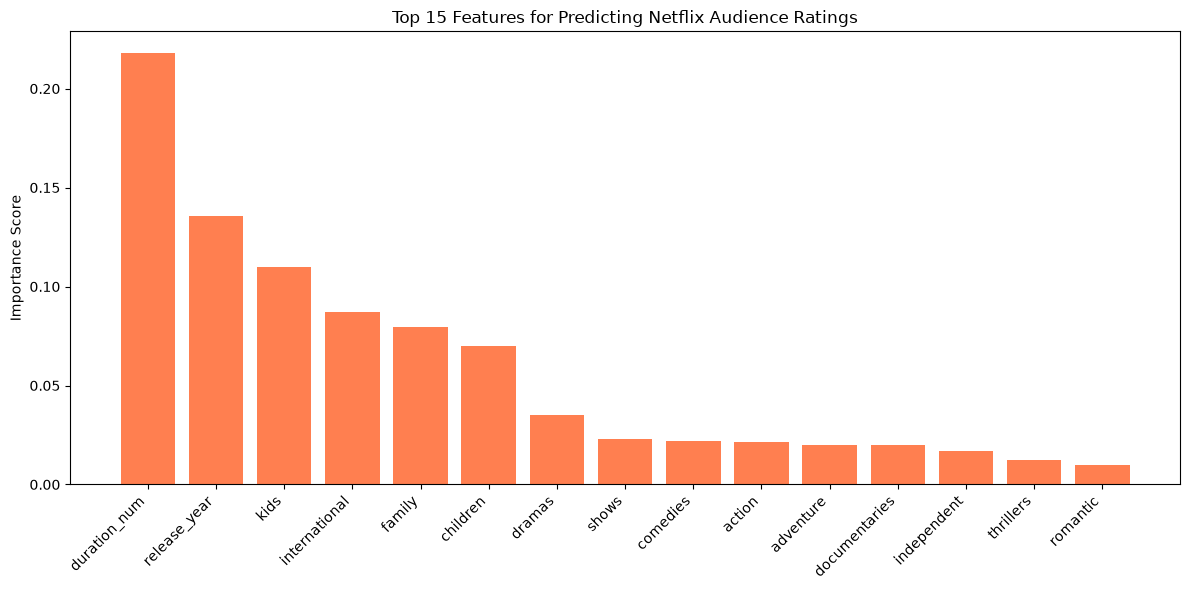


Top 15 Feature Importances:
duration_num: 0.2180
release_year: 0.1357
kids: 0.1101
international: 0.0870
family: 0.0795
children: 0.0697
dramas: 0.0349
shows: 0.0228
comedies: 0.0218
action: 0.0214
adventure: 0.0201
documentaries: 0.0200
independent: 0.0171
thrillers: 0.0125
romantic: 0.0100


In [4]:
import matplotlib.pyplot as plt

# 1. Get feature names
genre_features = tfidf.get_feature_names_out()
feature_names = np.append(genre_features, ['duration_num', 'release_year'])

# 2. Get importance from the FINAL model
importances = rf_final.feature_importances_

# 3. Sort
indices = np.argsort(importances)[::-1]

# 4. Plot Top 15
plt.figure(figsize=(12, 6))
plt.title("Top 15 Features for Predicting Netflix Audience Ratings")
plt.bar(range(15), importances[indices[:15]], align="center", color='coral')
plt.xticks(range(15), [feature_names[i] for i in indices[:15]], rotation=45, ha='right')
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

# Print the exact scores
print("\nTop 15 Feature Importances:")
for i in range(15):
    print(f"{feature_names[indices[i]]}: {importances[indices[i]]:.4f}")

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Define a deeper, wider grid
param_grid_v2 = {
    'n_estimators': [100, 200],             # More trees usually means better accuracy
    'max_depth': [None, 30, 50],            # Let the trees grow deep!
    'min_samples_split': [2, 5],            # Standard splitting rules
    'max_features': ['sqrt', 'log2']        # How many features to consider at each split
}

# 2. Initialize the base model
rf_base_v2 = RandomForestClassifier(random_state=42, class_weight='balanced')

# 3. Set up GridSearchCV
grid_search_v2 = GridSearchCV(
    estimator=rf_base_v2, 
    param_grid=param_grid_v2, 
    cv=3, 
    scoring='accuracy', # WE ARE NOW OPTIMIZING FOR PURE ACCURACY
    n_jobs=-1,          
    verbose=2           # verbose=2 gives a cleaner progress log
)

print("Starting Aggressive Hyperparameter Tuning...")
grid_search_v2.fit(X_train, y_train)

# 4. See the best settings found
print(f"\n✅ Best Parameters Found: {grid_search_v2.best_params_}")
print(f"✅ Best Cross-Validation Accuracy: {grid_search_v2.best_score_:.4f}")

Starting Aggressive Hyperparameter Tuning...
Fitting 3 folds for each of 24 candidates, totalling 72 fits

✅ Best Parameters Found: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}
✅ Best Cross-Validation Accuracy: 0.4654


In [6]:
# 1. Train the final V2 model with the best parameters
rf_final_v2 = RandomForestClassifier(
    max_depth=None, 
    max_features='sqrt',
    min_samples_split=5, 
    n_estimators=200, 
    random_state=42, 
    class_weight='balanced'
)

rf_final_v2.fit(X_train, y_train)

# 2. Predict and Evaluate
y_pred_v2 = rf_final_v2.predict(X_test)

print(f"🎯 V2 Model Test Accuracy: {accuracy_score(y_test, y_pred_v2) * 100:.2f}%\n")
print("📊 V2 Classification Report:")
print(classification_report(y_test, y_pred_v2))

🎯 V2 Model Test Accuracy: 45.05%

📊 V2 Classification Report:
              precision    recall  f1-score   support

       Other       0.13      0.24      0.17        70
          PG       0.38      0.59      0.46        58
       PG-13       0.34      0.48      0.40        98
           R       0.42      0.54      0.47       160
       TV-14       0.49      0.42      0.45       431
       TV-MA       0.67      0.48      0.56       641
       TV-PG       0.22      0.28      0.25       172
        TV-Y       0.51      0.61      0.55        61
       TV-Y7       0.48      0.51      0.49        67

    accuracy                           0.45      1758
   macro avg       0.40      0.46      0.42      1758
weighted avg       0.50      0.45      0.46      1758



In [7]:
# 1. Train the final V2 model with the best parameters
rf_final_v2 = RandomForestClassifier(
    max_depth=None, 
    max_features='sqrt',
    min_samples_split=5, 
    n_estimators=200, 
    random_state=42, 
    class_weight='balanced'
)

rf_final_v2.fit(X_train, y_train)

# 2. Predict and Evaluate
y_pred_v2 = rf_final_v2.predict(X_test)

print(f"🎯 V2 Model Test Accuracy: {accuracy_score(y_test, y_pred_v2) * 100:.2f}%\n")
print("📊 V2 Classification Report:")
print(classification_report(y_test, y_pred_v2))

🎯 V2 Model Test Accuracy: 45.05%

📊 V2 Classification Report:
              precision    recall  f1-score   support

       Other       0.13      0.24      0.17        70
          PG       0.38      0.59      0.46        58
       PG-13       0.34      0.48      0.40        98
           R       0.42      0.54      0.47       160
       TV-14       0.49      0.42      0.45       431
       TV-MA       0.67      0.48      0.56       641
       TV-PG       0.22      0.28      0.25       172
        TV-Y       0.51      0.61      0.55        61
       TV-Y7       0.48      0.51      0.49        67

    accuracy                           0.45      1758
   macro avg       0.40      0.46      0.42      1758
weighted avg       0.50      0.45      0.46      1758



In [8]:
from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# 1. Define the three base models
# We use the best parameters we found for the Random Forest
rf_ensemble = RandomForestClassifier(max_depth=None, n_estimators=100, min_samples_split=5, random_state=42, class_weight='balanced')
lr_ensemble = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
gb_ensemble = GradientBoostingClassifier(n_estimators=100, random_state=42)

# 2. Create the Voting Classifier
# voting='soft' means it uses the predicted probabilities, not just the hard class labels
voting_clf = VotingClassifier(
    estimators=[('rf', rf_ensemble), ('lr', lr_ensemble), ('gb', gb_ensemble)],
    voting='soft',
    n_jobs=-1
)

# 3. Train and Evaluate
print("Training Voting Ensemble...")
voting_clf.fit(X_train, y_train)

y_pred_vote = voting_clf.predict(X_test)
print(f"\n🎯 Ensemble Accuracy: {accuracy_score(y_test, y_pred_vote) * 100:.2f}%\n")
print("📊 Ensemble Classification Report:")
print(classification_report(y_test, y_pred_vote))

Training Voting Ensemble...

🎯 Ensemble Accuracy: 50.57%

📊 Ensemble Classification Report:
              precision    recall  f1-score   support

       Other       0.22      0.17      0.19        70
          PG       0.53      0.62      0.57        58
       PG-13       0.37      0.47      0.42        98
           R       0.46      0.54      0.50       160
       TV-14       0.48      0.48      0.48       431
       TV-MA       0.63      0.60      0.62       641
       TV-PG       0.32      0.25      0.28       172
        TV-Y       0.51      0.67      0.58        61
       TV-Y7       0.48      0.49      0.49        67

    accuracy                           0.51      1758
   macro avg       0.44      0.48      0.46      1758
weighted avg       0.50      0.51      0.50      1758



In [9]:
# 1. Create a Weighted Voting Classifier
# Weights: RF=2, LR=1, GB=2 (Trusting tree-based models more)
voting_clf_weighted = VotingClassifier(
    estimators=[('rf', rf_ensemble), ('lr', lr_ensemble), ('gb', gb_ensemble)],
    voting='soft',
    weights=[2, 1, 2], # THE MAGIC WEIGHTS
    n_jobs=-1
)

# 2. Train and Evaluate
print("Training Weighted Ensemble...")
voting_clf_weighted.fit(X_train, y_train)

y_pred_weighted = voting_clf_weighted.predict(X_test)
print(f"\n🎯 Weighted Ensemble Accuracy: {accuracy_score(y_test, y_pred_weighted) * 100:.2f}%\n")

Training Weighted Ensemble...

🎯 Weighted Ensemble Accuracy: 51.37%

